# Figure 3 -- the catalog schematic (`population_schematic_500pc`)

**Top:** the stellar down-selection from the full `G23H` release to the simulated sample. **Middle:**
every one of those stars is simulated in all three populations -- zero, one and two companions --
each drawn from the priors shown with no detectability filter. **Bottom:** the two high-SNR
sub-catalogs, selections over the populations above (every injected companion at
$\mathrm{SNR_{tot}} \ge 5$), not separate simulations.

Every number on the figure is read off the catalog: `stars.csv` for the parent-sample cuts, the
truth tables for the population sizes, the near-resonant counts and the high-SNR selections (which
are recomputed from the parent tables and checked against the stored `_high_snr` files). The two
counts the mirror cannot supply -- the rows of the full `G23H` release and of its 500 pc cut, with
their duplicate DR2 cross-match rows -- are read from the original inputs when they are on this
machine and taken from the recorded values otherwise.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/epochalypse_github/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/epochalypse_github/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/epochalypse_github/analysis/supplementary_figures


## 1. The numbers

The cuts are in the order the paper's Section 2 states them: parallax, the duplicate collapse, the
two per-CCD noise terms, and the two Pecaut & Mamajek cuts (the table's $M_G$ range for the mass interpolation, then the
main-sequence band about its dwarf ridge). Only the endpoint is invariant to the order.

In [2]:
import pyarrow as pa
import pyarrow.ipc as ipc
import pyarrow.parquet as pq

MAX_DIST_PC = 500.0
MIN_PLX_MAS = 1000.0 / MAX_DIST_PC
SNR_MIN = pf.C.HIGH_SNR_MIN

# ---- the full release and its 500 pc cut: read if present, recorded otherwise ----------
if pf.G23H_FULL.exists():
    with pa.memory_map(str(pf.G23H_FULL), "r") as src:
        n_g23h = ipc.open_file(src).get_batch(0).num_rows
else:
    n_g23h = pf.N_G23H_FULL_RECORDED
    print(f"note: {pf.G23H_FULL} not present; using the recorded row count")

if pf.G23H_500PC.exists():
    with pa.memory_map(str(pf.G23H_500PC), "r") as src:
        batch = ipc.open_file(src).get_batch(0)
        index = {f.name: i for i, f in enumerate(batch.schema)}
        g23h = pd.DataFrame({name: batch.column(index[name]).to_numpy(zero_copy_only=False)
                             for name in ("gaia_source_id", "sig_AL", "sig_att_radec")})
    n_within = len(g23h)
    dup_counts = g23h["gaia_source_id"].value_counts()
    g23h = g23h.drop_duplicates("gaia_source_id")
    n_unique = len(g23h)
    print(f"G23H within {MAX_DIST_PC:g} pc: {n_within:,} rows -> {n_unique:,} unique sources "
          f"({(dup_counts == 2).sum():,} appear twice, {(dup_counts == 3).sum()} three times)")
    has_sigal = np.isfinite(g23h["sig_AL"].to_numpy(float))
    has_sigatt = np.isfinite(g23h["sig_att_radec"].to_numpy(float))
    n_after_sigal = int(has_sigal.sum())
    n_after_noise = int((has_sigal & has_sigatt).sum())
    g23h_ids_noise = set(g23h["gaia_source_id"].to_numpy()[has_sigal & has_sigatt].astype("int64"))
else:
    print(f"note: {pf.G23H_500PC} not present; using the recorded counts for the first three cuts")
    n_within, n_unique = pf.N_G23H_500PC_RECORDED, pf.N_G23H_500PC_UNIQUE_RECORDED
    n_after_sigal, n_after_noise, g23h_ids_noise = n_unique - 1_080, n_unique - 1_080 - 14, None
drop_duplicate, drop_sigal, drop_sigatt = n_within - n_unique, n_unique - n_after_sigal, n_after_sigal - n_after_noise

# ---- the mirror: stars.csv is the P&M-interpolable set; the parent and simulated samples follow ----
stars = pf.star_columns(["gaia_source_id", "sig_AL", "sig_att_radec", "abs_G", "bp_rp_dr3", "parallax",
                         "mass_interp", "ra", "dec"])
in_parent = pf.parent_mask(stars)
in_simulated = in_parent & (pf.main_sequence_class(pf.main_sequence_offset(stars)) == "main_sequence")
n_catalog = int(in_parent.sum())          # the noise-complete P&M sample (the paper's old parent sample)
n_simulated = int(in_simulated.sum())
drop_pecaut = n_after_noise - n_catalog
drop_ms = n_catalog - n_simulated
if g23h_ids_noise is not None:
    # the P&M cut, measured: the noise-complete G23H sources that are in stars.csv
    _in_pecaut = pd.Series(list(g23h_ids_noise)).isin(stars["gaia_source_id"].astype("int64")).sum()
    assert _in_pecaut == n_catalog, (_in_pecaut, n_catalog)

# ---- the Pecaut & Mamajek ranges the last two cuts use, read from the table itself --------
_pm = pf.S.read_pecaut()
_pm_mass = _pm.dropna(subset=["M_G", "Msun", "R_Rsun"]).sort_values("M_G")
pm_mg_lo, pm_mg_hi = float(_pm_mass["M_G"].iloc[0]), float(_pm_mass["M_G"].iloc[-1])
pm_spt_lo, pm_spt_hi = _pm_mass["SpT"].iloc[0], _pm_mass["SpT"].iloc[-1]
_ridge = _pm.dropna(subset=["Bp-Rp", "M_G"])
_ridge = _ridge.loc[: _ridge.index[_ridge["SpT"] == pf.C.MS_RIDGE_LAST_SPT][0]]
ridge_bprp_lo, ridge_bprp_hi = float(_ridge["Bp-Rp"].iloc[0]), float(_ridge["Bp-Rp"].iloc[-1])
ridge_spt_lo, ridge_spt_hi = _ridge["SpT"].iloc[0], _ridge["SpT"].iloc[-1]
ms_class = pf.main_sequence_class(pf.main_sequence_offset(stars))
n_outside_colour = int((in_parent & (ms_class == "outside_colour_range")).sum())
print(f"P&M13 mass interpolation: M_G in [{pm_mg_lo:g}, {pm_mg_hi:g}] ({pm_spt_lo}--{pm_spt_hi}); "
      f"dwarf ridge: BP-RP in [{ridge_bprp_lo:g}, {ridge_bprp_hi:g}] ({ridge_spt_lo}--{ridge_spt_hi}), "
      f"band |Delta M_G| <= {pf.C.MS_FAINT_EDGE:g}; of the {drop_ms:,} main-sequence rejects, "
      f"{n_outside_colour:,} are outside the ridge's colour range")

# ---- populations ------------------------------------------------------------------------
n_pop = {name: pq.ParquetFile(pf.C.truths(name)).metadata.num_rows for name in ("0_companion", "1_companion", "2_companion")}
assert all(n == n_simulated for n in n_pop.values()), (n_pop, n_simulated)
sim_ids = pf.simulated_ids()
assert set(sim_ids) == set(stars.loc[in_simulated, "gaia_source_id"].astype("int64"))

# ---- the high-SNR sub-catalogs: re-derived from the parent tables, checked against the files ----
n_hs, n_res, n_res_hs = {}, {}, {}
for n in (1, 2):
    name = f"{n}_companion"
    cols = ["gaia_source_id", *(f"snr_total_{k}" for k in range(1, n + 1))] + (["near_resonance"] if n == 2 else [])
    parent = pd.read_parquet(pf.C.truths(name), columns=cols)
    selected = pf.select_high_snr(parent, SNR_MIN)
    stored = pq.ParquetFile(pf.C.truths(name, high_snr=True)).metadata.num_rows
    assert len(selected) == stored, f"{name}: stored high-SNR table has {stored:,} rows, the cut selects {len(selected):,}"
    n_hs[n] = len(selected)
    if n == 2:
        n_res[2] = int(parent["near_resonance"].sum())
        n_res_hs[2] = int(selected["near_resonance"].sum())

print(f"funnel: G23H {n_g23h:,} -> within {MAX_DIST_PC:g} pc {n_within:,} rows -> {n_unique:,} stars "
      f"(-{drop_duplicate:,} duplicate) -> {n_after_sigal:,} (-{drop_sigal:,} no sig_AL) -> {n_after_noise:,} "
      f"(-{drop_sigatt} no sig_att_radec) -> {n_catalog:,} (-{drop_pecaut:,} outside P&M13) "
      f"-> {n_simulated:,} (-{drop_ms:,} off the main sequence)")
print(f"pops  : 0c {n_pop['0_companion']:,} | 1c {n_pop['1_companion']:,} | 2c {n_pop['2_companion']:,}")
print(f"high-SNR (every SNR_tot >= {SNR_MIN:g}): 1c {n_hs[1]:,} | 2c {n_hs[2]:,}")
print(f"2c near-resonant: all {n_res[2]:,} | high-SNR {n_res_hs[2]:,}")

G23H within 500 pc: 5,789,521 rows -> 5,729,075 unique sources (60,392 appear twice, 27 three times)


P&M13 mass interpolation: M_G in [-1.19, 17.3] (B3V--L2V); dwarf ridge: BP-RP in [-0.12, 5.1] (B9V--M8.5V), band |Delta M_G| <= 1; of the 684,244 main-sequence rejects, 2,036 are outside the ridge's colour range


funnel: G23H 18,061,961 -> within 500 pc 5,789,521 rows -> 5,729,075 stars (-60,446 duplicate) -> 5,727,995 (-1,080 no sig_AL) -> 5,727,981 (-14 no sig_att_radec) -> 5,724,572 (-3,409 outside P&M13) -> 5,040,328 (-684,244 off the main sequence)
pops  : 0c 5,040,328 | 1c 5,040,328 | 2c 5,040,328
high-SNR (every SNR_tot >= 5): 1c 436,883 | 2c 25,946
2c near-resonant: all 16,615 | high-SNR 272


## 2. The figure

Five tiers: the funnel, the companion injection (the priors sit on the trunk because that is where
they act), the three generated populations, the catalog boundary, and the two derived sub-catalogs
beneath the populations they are drawn from.

  wrote analysis/paper_figures/population_schematic_500pc.pdf, analysis/paper_figures/population_schematic_500pc.png


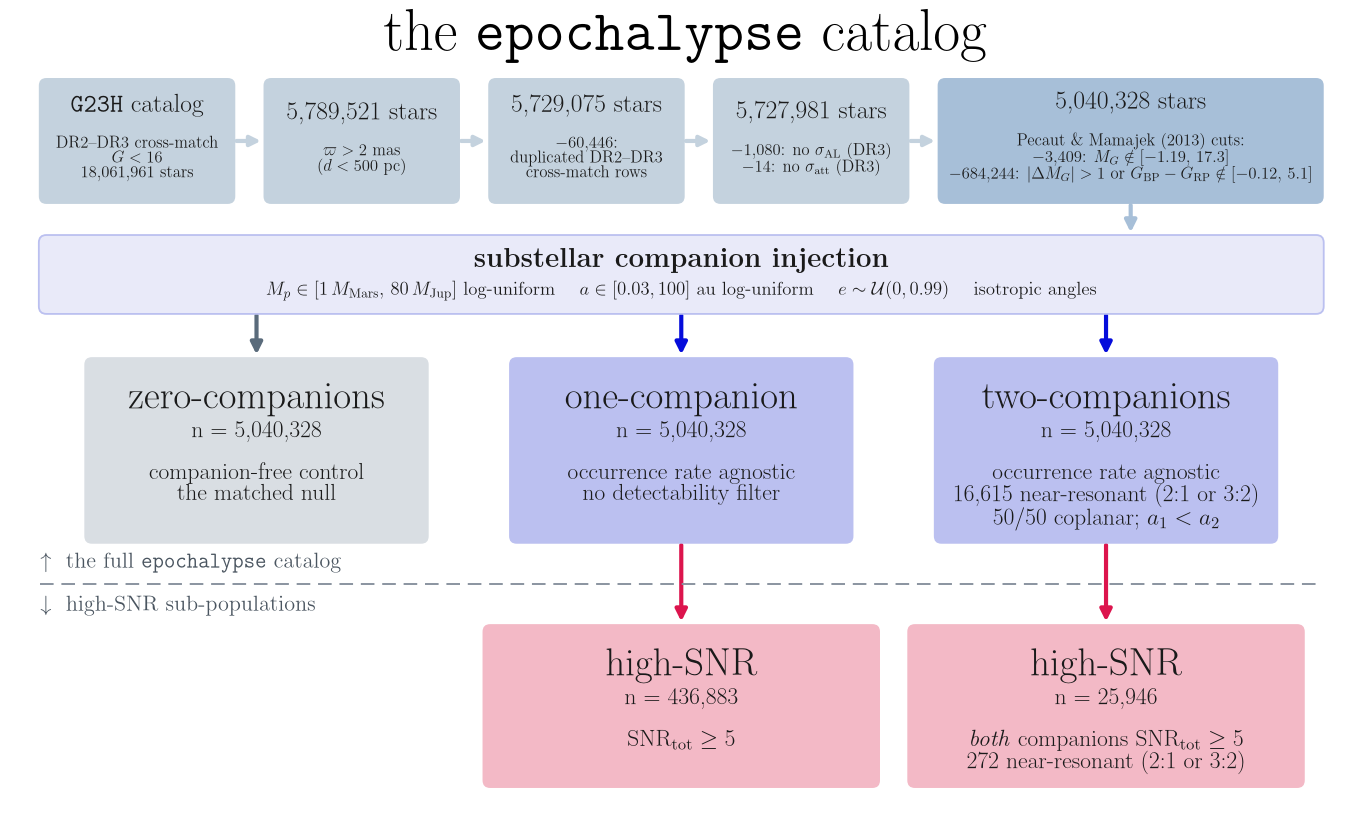

In [3]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

COL_CONTROL, COL_RANDOM, COL_HIGHSNR = "#D9DEE3", "#BBC0F0", "#F3B9C6"
COL_FUNNEL, COL_PARENT = "#C4D2DE", "#A7BFD8"
INK, ARROW_CTRL, ARROW_RAND, ARROW_SNR, RULE = pf.INK, "#5A6B7B", "#050CDB", "#DC144D", "#8A94A0"


def _points_per_unit(ax):
    width_in = ax.figure.get_size_inches()[0] * ax.get_position().width
    x0, x1 = ax.get_xlim()
    return (x1 - x0) / (72.0 * width_in)


def box(ax, cx, cy, w, h, facecolor, title, lines=None, textcolor=INK, fontsize=10.0, title_fs=12.0,
        edgecolor="none", lw=1.4, zorder=3, gap=0.16, top_pad=None):
    """Rounded box. The title+body block is vertically centred on `cy`; with `top_pad` (data units) the
    title top is instead anchored that far below the box top, so boxes in a row share a title height."""
    x, y = cx - w / 2, cy - h / 2
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.10",
                                linewidth=lw, facecolor=facecolor, edgecolor=edgecolor, zorder=zorder))
    if lines:
        title_h = title_fs * _points_per_unit(ax)
        top0 = cy + h / 2.0
        t_title = ax.text(cx, top0, title, ha="center", va="top", fontsize=title_fs, fontweight="bold",
                          color=textcolor, zorder=zorder + 1)
        t_body = ax.text(cx, top0 - title_h - gap, "\n".join(lines), ha="center", va="top",
                         fontsize=fontsize, color=textcolor, zorder=zorder + 1, linespacing=1.45)
        fig = ax.figure
        fig.canvas.draw()
        rend = fig.canvas.get_renderer()
        inv = ax.transData.inverted()

        def _yspan(t):
            bb = t.get_window_extent(rend)
            (_, ylo), (_, yhi) = inv.transform([(bb.x0, bb.y0), (bb.x0, bb.y1)])
            return ylo, yhi

        tlo, thi = _yspan(t_title)
        blo, bhi = _yspan(t_body)
        dy = -top_pad if top_pad is not None else cy - 0.5 * (max(thi, bhi) + min(tlo, blo))
        t_title.set_y(top0 + dy)
        t_body.set_y(top0 - title_h - gap + dy)
    else:
        ax.text(cx, cy, title, ha="center", va="center", fontsize=title_fs, fontweight="bold",
                color=textcolor, zorder=zorder + 1)
    return {"L": (x, cy), "R": (x + w, cy), "T": (cx, y + h), "B": (cx, y)}


def arrow(ax, p0, p1, color=INK, lw=1.9, rad=0.0, mutation_scale=15):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=mutation_scale, lw=lw,
                                 color=color, connectionstyle=f"arc3,rad={rad}", zorder=1, shrinkA=2, shrinkB=3))


tex = pf.tex_num

# ---- geometry (data units; the axes is aspect-equal) ----
X0, X1 = 0.20, 18.00
Y0, Y1 = 2.51, 12.40
FIG_W = 15.0
fig, ax = plt.subplots(figsize=(FIG_W, FIG_W * (Y1 - Y0) / (X1 - X0)))
ax.set_xlim(X0, X1); ax.set_ylim(Y0, Y1)
ax.set_aspect("equal"); ax.axis("off")

Y_FUNNEL, H_FUNNEL, W_FUNNEL = 11.37, 1.62, 2.55      # tier 1: the funnel, five boxes
W_FUNNEL_LAST = 5.05                                   # the merged Pecaut & Mamajek box is wider
Y_BAR, H_BAR = 9.61, 1.00                              # tier 2: companion injection
Y_POP, H_POP, W_POP = 7.29, 2.42, 4.50                 # tier 3: generated populations
Y_RULE = 5.53                                          # the catalog boundary
Y_SUB, H_SUB, W_SUB = 3.92, 2.12, 5.20                 # tier 4: derived sub-catalogs
X_LEFT, X_RIGHT = 0.60, 17.50
_widths = [W_FUNNEL] * 4 + [W_FUNNEL_LAST]
_gap = (X_RIGHT - X_LEFT - sum(_widths)) / (len(_widths) - 1)
_edges = np.concatenate([[X_LEFT], X_LEFT + np.cumsum([w + _gap for w in _widths])])
X_FUNNEL = [_edges[i] + _widths[i] / 2 for i in range(len(_widths))]
X_ZERO, X_ONE, X_TWO = 3.45, 9.05, 14.65
FUN_TITLE, FUN_BODY = 18.5, 12.0

# ================= tier 1: the selection funnel, left -> right =================
g0 = box(ax, X_FUNNEL[0], Y_FUNNEL, W_FUNNEL, H_FUNNEL, COL_FUNNEL, r"\texttt{G23H} catalog",
         [r"DR2--DR3 cross-match", r"$G<16$", f"{n_g23h:,} stars"], title_fs=FUN_TITLE, fontsize=FUN_BODY)
g1 = box(ax, X_FUNNEL[1], Y_FUNNEL, W_FUNNEL, H_FUNNEL, COL_FUNNEL, f"{n_within:,} stars",
         [rf"$\varpi>{MIN_PLX_MAS:g}$ mas", rf"($d<{MAX_DIST_PC:g}$ pc)"], title_fs=FUN_TITLE, fontsize=FUN_BODY)
g2 = box(ax, X_FUNNEL[2], Y_FUNNEL, W_FUNNEL, H_FUNNEL, COL_FUNNEL, f"{n_unique:,} stars",
         [rf"$-{tex(drop_duplicate)}$:", r"duplicated DR2--DR3", r"cross-match rows"], title_fs=FUN_TITLE, fontsize=FUN_BODY)
g3 = box(ax, X_FUNNEL[3], Y_FUNNEL, W_FUNNEL, H_FUNNEL, COL_FUNNEL, f"{n_after_noise:,} stars",
         [rf"$-{tex(drop_sigal)}$: no $\sigma_{{\rm AL}}$ (DR3)", rf"$-{tex(drop_sigatt)}$: no $\sigma_{{\rm att}}$ (DR3)"],
         title_fs=FUN_TITLE, fontsize=FUN_BODY)
par = box(ax, X_FUNNEL[4], Y_FUNNEL, W_FUNNEL_LAST, H_FUNNEL, COL_PARENT, f"{n_simulated:,} stars",
          [r"Pecaut \& Mamajek (2013) cuts:",
           rf"$-{tex(drop_pecaut)}$: $M_G\notin[{pm_mg_lo:g},\,{pm_mg_hi:g}]$",
           rf"$-{tex(drop_ms)}$: $|\Delta M_G|>{pf.C.MS_FAINT_EDGE:g}$ or "
           rf"$G_{{\rm BP}}-G_{{\rm RP}}\notin[{ridge_bprp_lo:g},\,{ridge_bprp_hi:g}]$"],
          title_fs=FUN_TITLE, fontsize=FUN_BODY)
for left, right in ((g0, g1), (g1, g2), (g2, g3), (g3, par)):
    arrow(ax, left["R"], right["L"], color=COL_FUNNEL, lw=3.0, mutation_scale=15)

# ================= tier 2: the injection bus ==================================
_mass_min_mars = pf.C.MASS_MIN_MJUP / pf.C.MARS_IN_MJUP
ax.add_patch(FancyBboxPatch((X_LEFT, Y_BAR - H_BAR / 2), X_RIGHT - X_LEFT, H_BAR,
                            boxstyle="round,pad=0.02,rounding_size=0.10", facecolor="#E9EAF9",
                            edgecolor=COL_RANDOM, linewidth=1.3, zorder=3))
ax.text(0.5 * (X_LEFT + X_RIGHT), Y_BAR + 0.19,
        r"\textbf{substellar companion injection}",
        ha="center", va="center", fontsize=20, color=INK, zorder=4)
ax.text(0.5 * (X_LEFT + X_RIGHT), Y_BAR - 0.21,
        rf"$M_p\in[{_mass_min_mars:.3g}\,M_{{\rm Mars}},\,{pf.C.MASS_MAX_MJUP:g}\,M_{{\rm Jup}}]$ log-uniform \quad "
        rf"$a\in[{pf.C.A_MIN_AU:g},{pf.C.A_MAX_AU:g}]$ au log-uniform \quad "
        rf"$e\sim\mathcal{{U}}({pf.C.ECC_MIN:g},{pf.C.ECC_MAX:g})$ \quad isotropic angles",
        ha="center", va="center", fontsize=13.5, color=INK, zorder=4)
arrow(ax, par["B"], (X_FUNNEL[4], Y_BAR + H_BAR / 2), color=COL_PARENT, lw=3.0, mutation_scale=17)

# ================= tier 3: the three generated populations ====================
p0 = box(ax, X_ZERO, Y_POP, W_POP, H_POP, COL_CONTROL, "zero-companions",
         [f"n = {n_pop['0_companion']:,}", "", r"companion-free control", r"the matched null"], title_fs=28, fontsize=17, gap=-0.08, top_pad=0.30)
p1 = box(ax, X_ONE, Y_POP, W_POP, H_POP, COL_RANDOM, "one-companion",
         [f"n = {n_pop['1_companion']:,}", "", r"occurrence rate agnostic", r"no detectability filter"], title_fs=28, fontsize=17, gap=-0.08, top_pad=0.30)
p2 = box(ax, X_TWO, Y_POP, W_POP, H_POP, COL_RANDOM, "two-companions",
         [f"n = {n_pop['2_companion']:,}", "", r"occurrence rate agnostic", rf"{tex(n_res[2])} near-resonant (2:1 or 3:2)",
          r"50/50 coplanar; $a_1<a_2$"], title_fs=28, fontsize=17, gap=-0.08, top_pad=0.30)
for target, colour in ((p0, ARROW_CTRL), (p1, ARROW_RAND), (p2, ARROW_RAND)):
    arrow(ax, (target["T"][0], Y_BAR - H_BAR / 2), target["T"], color=colour, lw=3.0, mutation_scale=17)

# ================= the catalog boundary =======================================
ax.plot([X_LEFT, X_RIGHT], [Y_RULE, Y_RULE], color=RULE, lw=1.4, ls=(0, (7, 4)), zorder=2)
ax.text(X_LEFT, Y_RULE + 0.15, r"$\uparrow$~~the full \texttt{epochalypse} catalog", ha="left", va="bottom",
        fontsize=16, color="#4a5560")
ax.text(X_LEFT, Y_RULE - 0.15, r"$\downarrow$~~high-SNR sub-populations", ha="left", va="top",
        fontsize=16, color="#4a5560")

# ================= tier 4: the two derived sub-catalogs =======================
s1 = box(ax, X_ONE, Y_SUB, W_SUB, H_SUB, COL_HIGHSNR, "high-SNR",
         [f"n = {n_hs[1]:,}", "", rf"$\mathrm{{SNR_{{tot}}}}\geq{SNR_MIN:g}$"], title_fs=28, fontsize=17, gap=-0.08, top_pad=0.30)
s2 = box(ax, X_TWO, Y_SUB, W_SUB, H_SUB, COL_HIGHSNR, "high-SNR",
         [f"n = {n_hs[2]:,}", "", rf"\emph{{both}} companions $\mathrm{{SNR_{{tot}}}}\geq{SNR_MIN:g}$",
          rf"{tex(n_res_hs[2])} near-resonant (2:1 or 3:2)"], title_fs=28, fontsize=17, gap=-0.08, top_pad=0.30)
for parent_box, child in ((p1, s1), (p2, s2)):
    arrow(ax, parent_box["B"], child["T"], color=ARROW_SNR, lw=3.0, mutation_scale=17)

ax.set_title(r"the \texttt{epochalypse} catalog", fontsize=42, fontweight="bold", pad=6)
plt.tight_layout()
pf.save(fig, "population_schematic_500pc", dpi=300, paper=True)
plt.show()